In [1]:
## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "DesyneMartinez"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}
## Set working drive to today's lecture:

setwd("STAT-7110-Quality-Control//Assignments//HW4")

## Homework 4 - Analysis Using Hotelling's $T^2$ and Multiple Stream Process Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: November 20, 2026 via D2L**

## Instructions:

You are the director of The Owl's Nest, a psychological services program at a local university that employs a team of four Clinical Psychology PhD students to offer counseling services to the campus community at a steep discount. When a new client comes in, they commit to biweekly sessions for at least one semester. At the start of each session, the client completes a brief survey assessing depressive symptoms using Likert-scale items (e.g., "How much do you agree with this statement, on a scale from 1 (strongly disagree) to 5 (strongly agree)?"). The total score ranges from 20 to 100, with higher scores indicating more severe depressive symptoms.

If a counselor's client scores begin trending upward over time, that may indicate a need for you, as the director, to step in -- whether by providing additional training and supervision, or by referring a client to a higher level of care. Because all four counselors work in the same training program, share office space and supervision, and often see clients during the same high-stress points in the academic calendar (midterms, finals), you suspect their clients' scores may be correlated with one another from week to week, rather than behaving as four completely independent processes.

To monitor this, you perform an initial Phase I analysis, jointly monitoring the scores of all four counselors across the 16-week fall semester, taking a sample of 5 clients per week for each counselor. After confirming statistical control, you'll monitor the subsequent 16-week spring semester (Phase II) to determine whether anything has changed.

## Key Specifications

| Quantity | Value |
|---|---|
| Quality characteristic | Total depressive-symptom survey score (20-100 scale) |
| Number of counselors (streams) | 4 |
| Clients sampled per counselor per week (n) | 5 |
| Phase I weeks (m) | 16 (fall semester) |
| Phase II weeks (m) | 16 (spring semester) |
| Control Chart for Each Stream design value | $L = 3.46$ |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

The purpose of this Analysis is to identify the depressive symptoms of college students after visiting clinical psychology PHD students for counseling. The students go biweekly then submit surveys at the start of the sessions over a 16 week semester and if it is noticeable that a counselor's client scores begin trending upward over time then it would indicate the need for additional training and/or supervision for one or more counselors.

### Q2: Identify the quality characteristic being monitored, and classify its measurement scale. Why might it be reasonable to suspect that the four counselors' weekly scores are correlated with one another, rather than fully independent?

The quality characteristic that is being monitored is the Total Depressive Symptom survey score. This score is a numeric value on a 20-100 measurement scale with 20 indicating less depressive symptoms and 100 indicating much higher depressive symptoms. Since these counselors work in the same training program, share the same office space and supervision, and deal with college students during a semester facing potentially rigorous midterms, exams, and assignments. Its highly likely that the Depressive symptom scores that these indivisual students submit for their respective counselors would be correlated with each other due to the seeing them during the most stressful moments during a semester.

### Q3: Given your answer to Q2, briefly explain why it might be reasonable to treat this scenario as a **multivariate process** (suggesting a Hotelling's $T^2$ chart) rather than a **multiple stream process** (suggesting the Control Chart for Each Stream technique). Under what different assumption would the opposite framing make more sense?

We want to use a Hotelling's T^2 chart here because we are assuming that the processes (The four counselors with their depressive scores from students) are correlated with each other. Given the scenario if the sessions for each counselor where different, they didn't share the same workspace, had a different supervisor, or the scores were taken from different semesters then they would be classified as independent from each other and a Multiple stream process technique would be needed instead.


## Analyze

### Q4: Read the Phase I data (`Counselling_PhaseI.xlsx`) into R as a list, one data frame per counselor (HINT: use `qcc::mqcc`, and make sure to remove the `Week` column from each data frame, possibly using `lapply`). Construct a Phase I Hotelling's $T^2$ chart. Do we have evidence of statistical control? Why or why not?

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Package 'qcc' version 2.7

Type 'citation("qcc")' for citing this R package in publications.



Rows: 16
Columns: 6
$ Week    <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16
$ Client1 <dbl> 39.99, 52.35, 43.68, 64.21, 40.45, 40.04, 40.95, 29.69, 48.40,…
$ Client2 <dbl> 46.47, 51.26, 42.97, 44.69, 43.92, 45.34, 55.74, 54.41, 43.09,…
$ Client3 <dbl> 38.31, 45.60, 50.58, 50.52, 54.42, 37.71, 43.28, 31.68, 53.47,…
$ Client4 <dbl> 57.76, 29.09, 49.45, 45.22, 32.81, 46.26, 43.56, 41.29, 52.09,…
$ Client5 <dbl> 47.64, 49.96, 39.49, 39.05, 49.75, 39.76, 44.20, 36.07, 40.05,…
List of 1
 $ Counselor1: tibble [16 × 5] (S3: tbl_df/tbl/data.frame)
  ..$ Client1: num [1:16] 40 52.4 43.7 64.2 40.5 ...
  ..$ Client2: num [1:16] 46.5 51.3 43 44.7 43.9 ...
  ..$ Client3: num [1:16] 38.3 45.6 50.6 50.5 54.4 ...
  ..$ Client4: num [1:16] 57.8 29.1 49.5 45.2 32.8 ...
  ..$ Client5: num [1:16] 47.6 50 39.5 39 49.8 ...
List of 1
 $ Counselor2: tibble [16 × 5] (S3: tbl_df/tbl/data.frame)
  ..$ Client1: num [1:16] 37.2 46.8 39.2 52.2 46.2 ...
  ..$ Client2: num [1:16] 49.2 45.7 47.2 31.1 52.8

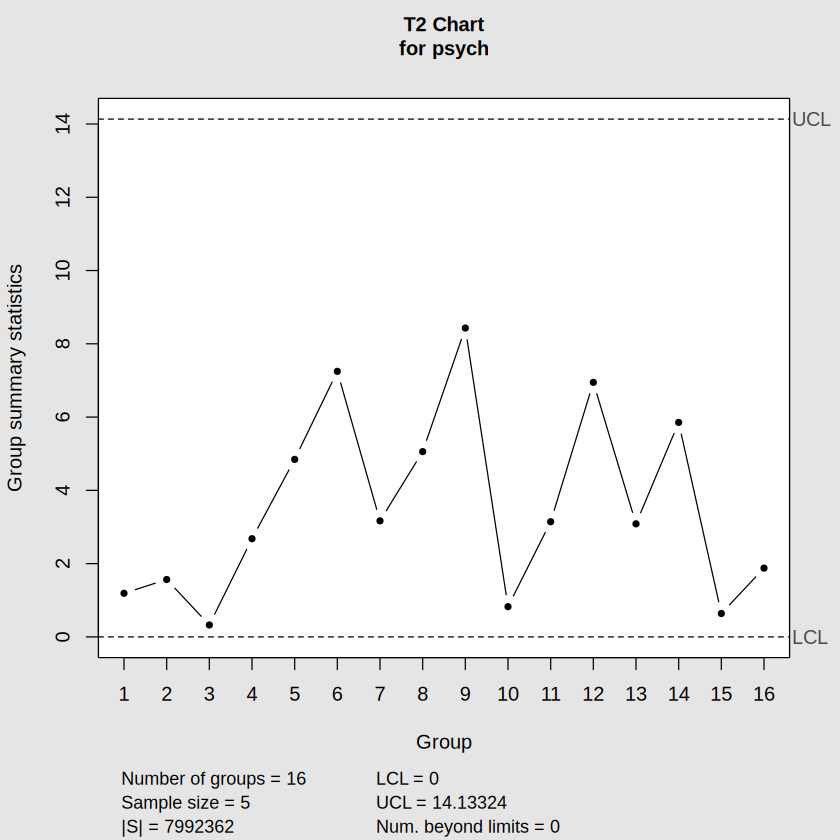

In [2]:
## Q4 Code ##


## Load the libraries ##
install.packages("qcc")
library(tidyverse)
library(readxl)
library(qcc)

## Read in the Dataset A ##

Counsel <- read_excel("Counselling_PhaseI.xlsx")

## Data Integrity Check ##

Counsel |>
  glimpse()


## Note, each Counselor is in a separate sheet of the Excel file, so we will read in each sheet as a separate data frame and store them in a list. ##

## Get Sheet Names and read in one Data Frame per Counselor ##

sn <- excel_sheets("Counselling_PhaseI.xlsx")

psych <- lapply(sn,FUN=function(x){

  d <- read_xlsx("Counselling_PhaseI.xlsx",sheet=x) %>%
    dplyr::select(`week`,`Client1`,`Client2`,`Client3`,`Client4`,`Client5`)

  return(d)

})

names(psych) <- paste("Counselor",1:4,sep="")



psych["Counselor1"] |> glimpse()

psych["Counselor2"] |> glimpse()

psych["Counselor3"] |> glimpse()

psych["Counselor4"] |> glimpse()


## Use mqcc to Plot the Phase 1 Chart! ##

t2 <- mqcc(psych,type='T2')


### Q5: Report the sample mean vector and sample variance-covariance matrix from Q4.

In [3]:
## Q5 Code ##
t2$center

Counselor1 Counselor2 Counselor3 Counselor4 
  45.34275   46.00288   45.28650   45.45975

In [ ]:
t2$cov

,Counselor1,Counselor2,Counselor3,Counselor4
Counselor1,64.94685,25.20394,18.73784,28.36822
Counselor2,25.20394,63.96758,30.76070,26.36930
Counselor3,18.73784,30.76070,67.29034,14.95226
Counselor4,28.36822,26.36930,14.95226,60.67095


### Q6: Read the Phase II data (`Counselling_PhaseII.xlsx`) into R the same way. Using the mean vector and covariance matrix from Q5, construct a Phase II Hotelling's $T^2$ chart. Do we still have evidence of statistical control? If not, generate individual univariate Shewhart $\bar{X}$ and $s$ charts (using the appropriate mean and standard deviation from Phase I) to determine which counselor(s) may have out-of-control scores.

In [4]:
## Q6 Code ##

## Read in Phase II Can Volume Data ##

sn2 <- excel_sheets("Counselling_PhaseII.xlsx")

psych2 <- lapply(sn2,FUN=function(x){

  d <- read_xlsx("Counselling_PhaseII.xlsx",sheet=x) %>%
    dplyr::select(`Client1`,`Client2`,`Client3`,`Client4`,`Client5`)

  return(d)

})

names(psych2) <- paste("Counselor",1:4,sep="")

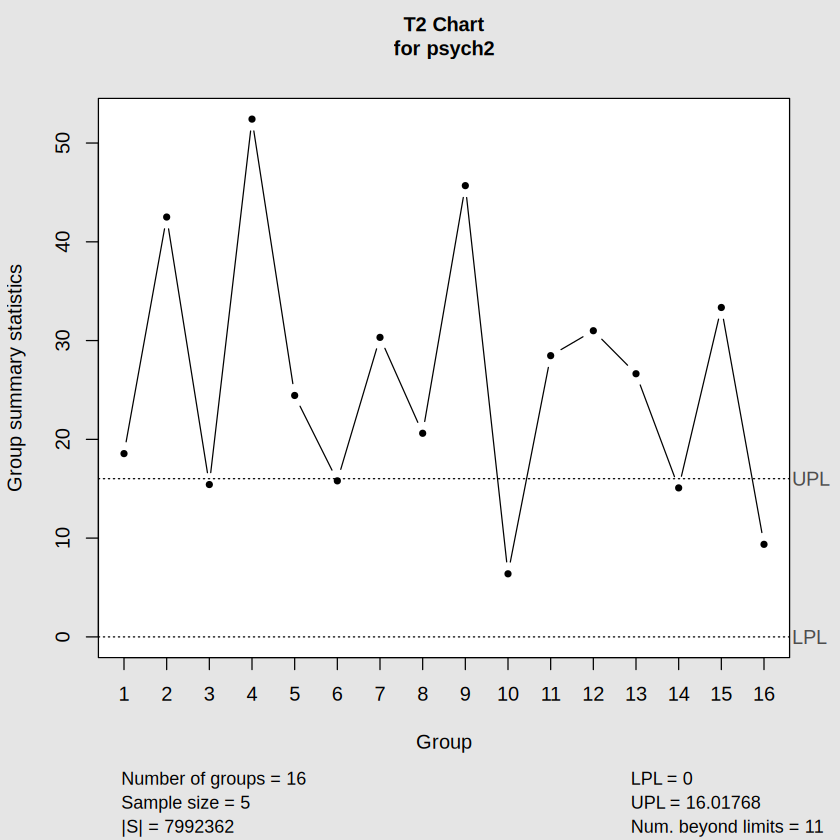

In [ ]:
## Use mqcc to Plot the Phase II Chart! ##

Counsel2 <- mqcc(psych2,type="T2",
           center=t2$center,
           cov=t2$cov,
           limits=F,pred.limits=T,
           plot=T)

In [5]:
lapply(psych2,FUN=function(x){

  return(mean(rowMeans(x)))

})

$Counselor1
[1] 46.16112

$Counselor2
[1] 44.43162

$Counselor3
[1] 59.6185

$Counselor4
[1] 44.552

In [6]:
# the bias correction constant for c4 for n=5 is 0.93999

c4 = .93999

counsel1_xbar <- t2$center[1]
counsel2_xbar <- t2$center[2]
counsel3_xbar <- t2$center[3]
counsel4_xbar <- t2$center[4]

counsel1_sd <- sqrt(t2$cov[1,1])/c4
counsel2_sd <- sqrt(t2$cov[2,2])/c4
counsel3_sd <- sqrt(t2$cov[3,3])/c4
counsel4_sd <- sqrt(t2$cov[4,4])/c4

In [7]:
## Calculate UCL & LCL ##

counsel1_ucl <- counsel1_xbar + 3*counsel1_sd
counsel1_lcl <- counsel1_xbar - 3*counsel1_sd

counsel2_ucl <- counsel2_xbar + 3*counsel2_sd
counsel2_lcl <- counsel2_xbar - 3*counsel2_sd

counsel3_ucl <- counsel3_xbar + 3*counsel3_sd
counsel3_lcl <- counsel3_xbar - 3*counsel3_sd

counsel4_ucl <- counsel4_xbar + 3*counsel4_sd
counsel4_lcl <- counsel4_xbar - 3*counsel4_sd

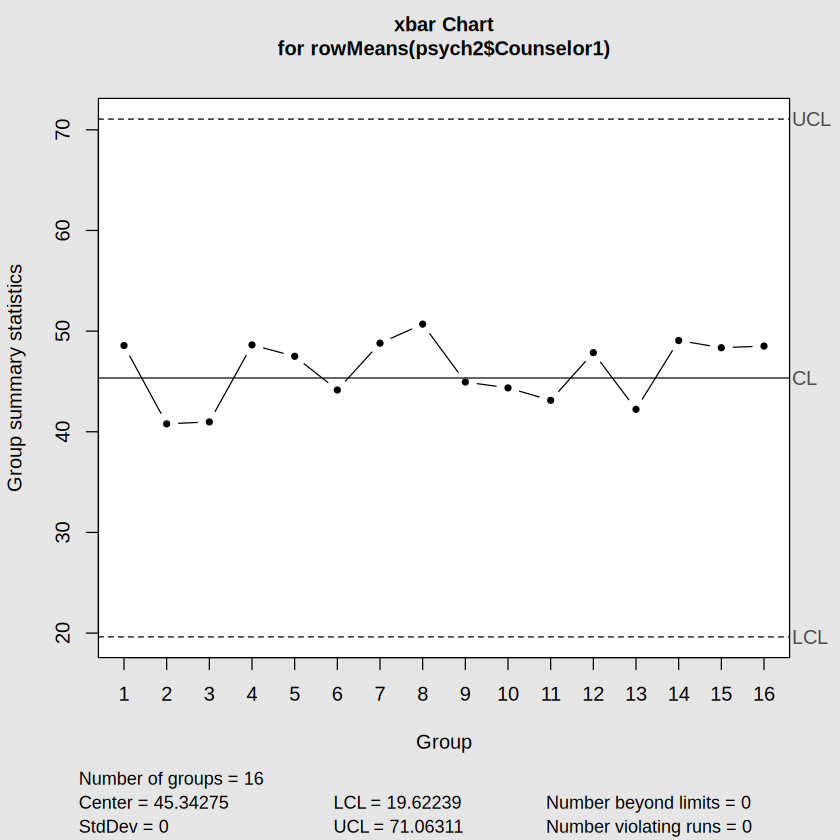

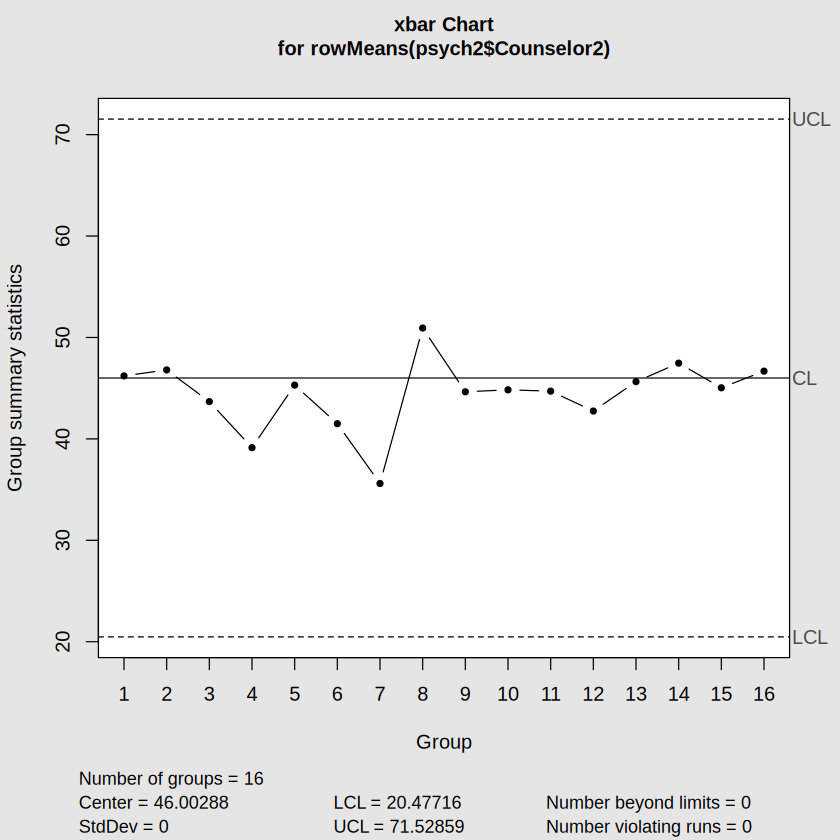

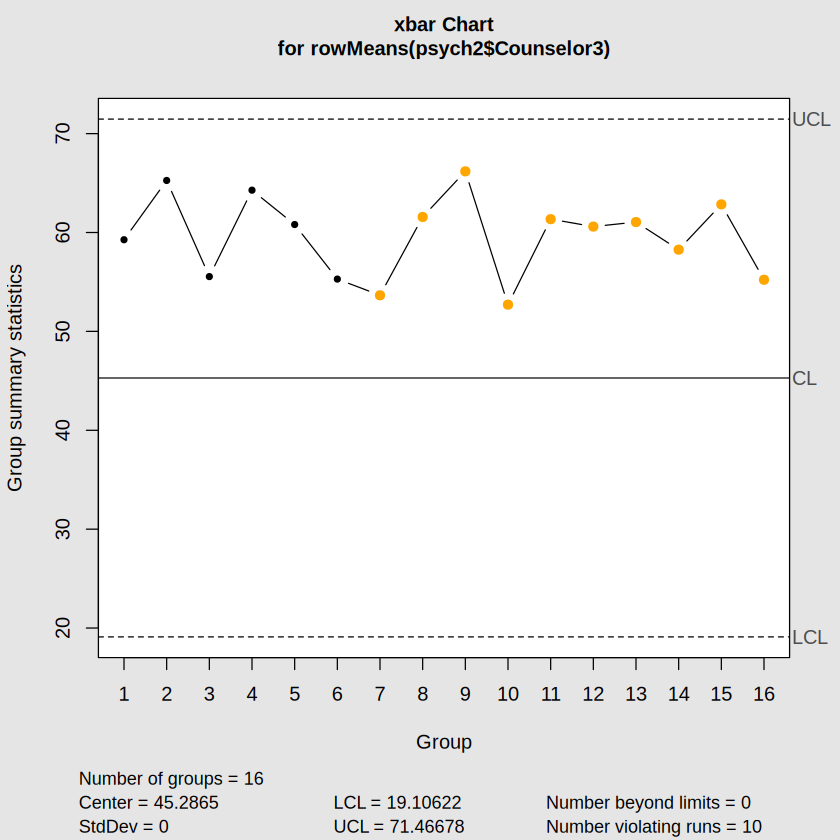

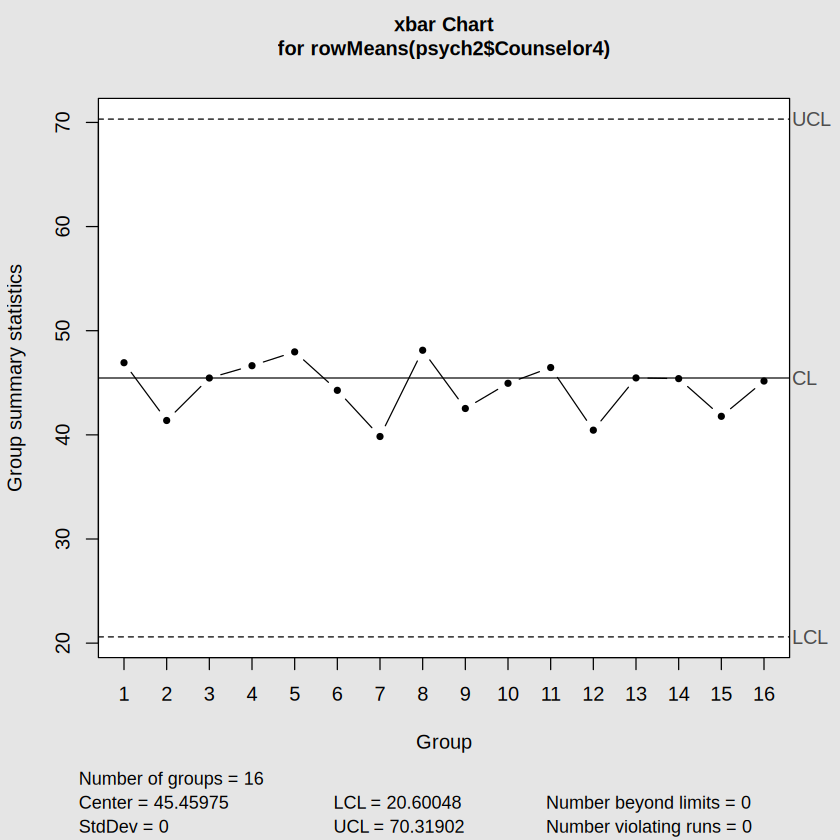

In [8]:
xbar1 <- qcc(rowMeans(psych2$Counselor1),
             type="xbar",
             center=counsel1_xbar,
             sigma=counsel1_sd,
             sizes=10,
             limits=c(counsel1_lcl,counsel1_ucl))

xbar2 <- qcc(rowMeans(psych2$Counselor2),
             type="xbar",
             center=counsel2_xbar,
             sigma=counsel2_sd,
             sizes=10,
             limits=c(counsel2_lcl,counsel2_ucl))

  xbar3 <- qcc(rowMeans(psych2$Counselor3),
             type="xbar",
             center=counsel3_xbar,
             sigma=counsel3_sd,
             sizes=10,
             limits=c(counsel3_lcl,counsel3_ucl))

  xbar4 <- qcc(rowMeans(psych2$Counselor4),
             type="xbar",
             center=counsel4_xbar,
             sigma=counsel4_sd,
             sizes=10,
             limits=c(counsel4_lcl,counsel4_ucl))

### Q7: What is the benefit of using a multivariate control chart over several separate univariate control charts? What is one limitation?

## Improve

### Q8: Based on your findings in Q6, briefly describe what intervention(s) you, as the director, might reasonably take regarding the counselor(s) flagged as out of control.

## Control

### Q9: It is reasonable to assume that this same monitoring situation could also be conceptualized as a **multiple stream process (MSP)** -- that is, treating the four counselors as independent, parallel processes rather than a single correlated multivariate one. Perform the same Phase I analysis as before, but using the Control Chart for Each Stream MSP technique ($L = 3.46$). Do we have evidence of statistical control?

In [23]:
## Q9 Code ##

library(tidyverse)
library(readxl)
library(qcc)

## Path to your Excel file ##
file_path <- "Counselling_PhaseI.xlsx"

## Get all sheet names ##
sheet_names <- excel_sheets(file_path)

## Read each sheet, select relevant columns, and add counselor name ##
psych_list <- lapply(sheet_names, function(sn) {
  d <- read_excel(file_path, sheet = sn) %>%
    dplyr::select(Client1, Client2, Client3, Client4, Client5) %>%
    mutate(Counselor = sn)  # Add sheet name as Counselor column
  return(d)
})

## Merge all sheets into one dataset ##
psych <- bind_rows(psych_list)

## View merged dataset ##
glimpse(psych)

Rows: 64
Columns: 6
$ Client1   <dbl> 39.99, 52.35, 43.68, 64.21, 40.45, 40.04, 40.95, 29.69, 48.4…
$ Client2   <dbl> 46.47, 51.26, 42.97, 44.69, 43.92, 45.34, 55.74, 54.41, 43.0…
$ Client3   <dbl> 38.31, 45.60, 50.58, 50.52, 54.42, 37.71, 43.28, 31.68, 53.4…
$ Client4   <dbl> 57.76, 29.09, 49.45, 45.22, 32.81, 46.26, 43.56, 41.29, 52.0…
$ Client5   <dbl> 47.64, 49.96, 39.49, 39.05, 49.75, 39.76, 44.20, 36.07, 40.0…
$ Counselor <chr> "Counselor1", "Counselor1", "Counselor1", "Counselor1", "Cou…


In [24]:
# A Control Chart for Each Stream Approach ##

## Split up Phase I Data by CarWashID ##

p1 <- split(psych,psych$Counselor)

In [25]:
## Now, p1 is a list where each element of the list is a dataframe --
## one for each counselor ##

## Calculate Means & Ranges ##

samp_list <- lapply(p1,FUN=function(x){

  df <- tibble(Means = rowMeans(x[,-6]),
               Ranges =
                 apply(x[,-6],1,FUN=function(x){

                   max(x) - min(x)

                 }),
                Counselor = x$Counselor,
                Week = seq(1,16))

  return(df)

})

In [28]:
## Calculate Control Limits & Plot Charts ##
install.packages("IQCC")
library(IQCC)

d2 <- d2(5)

L <- 3.46

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘miscTools’


Loading required package: miscTools



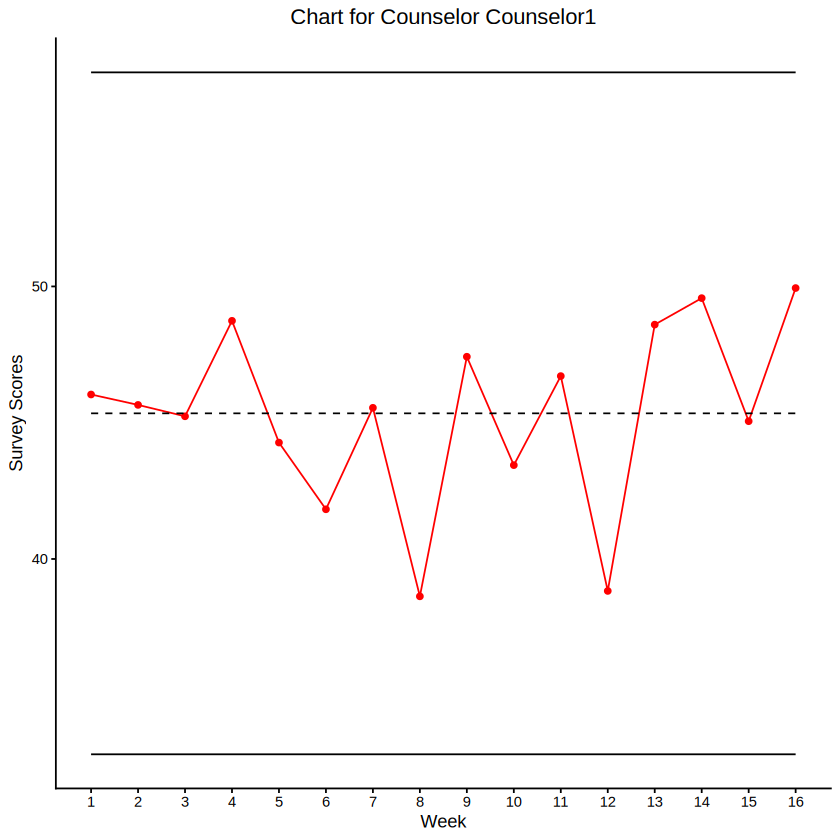

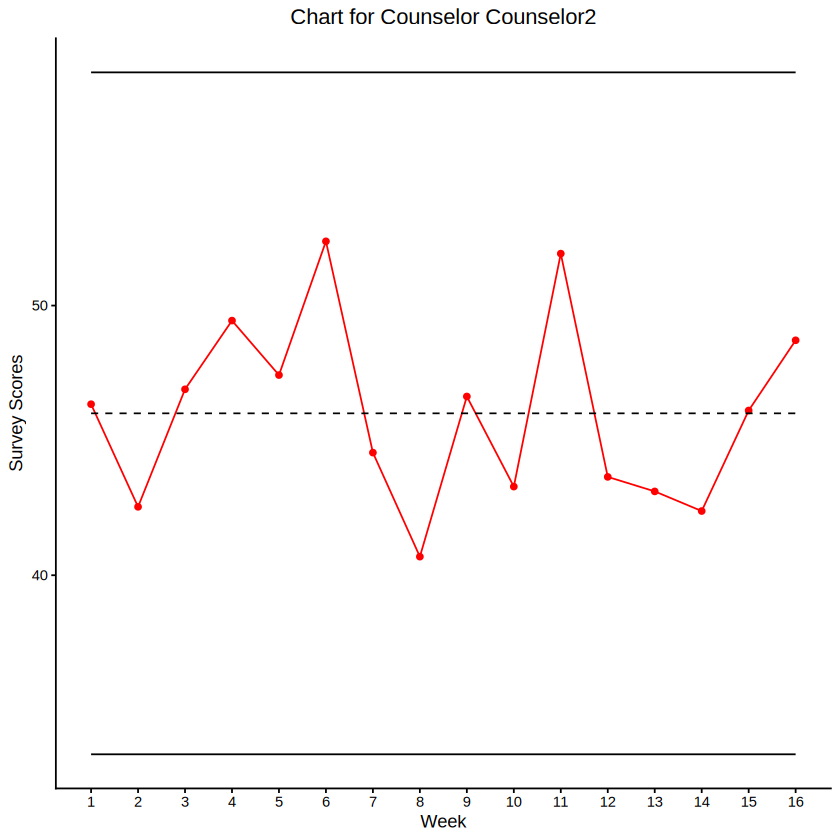

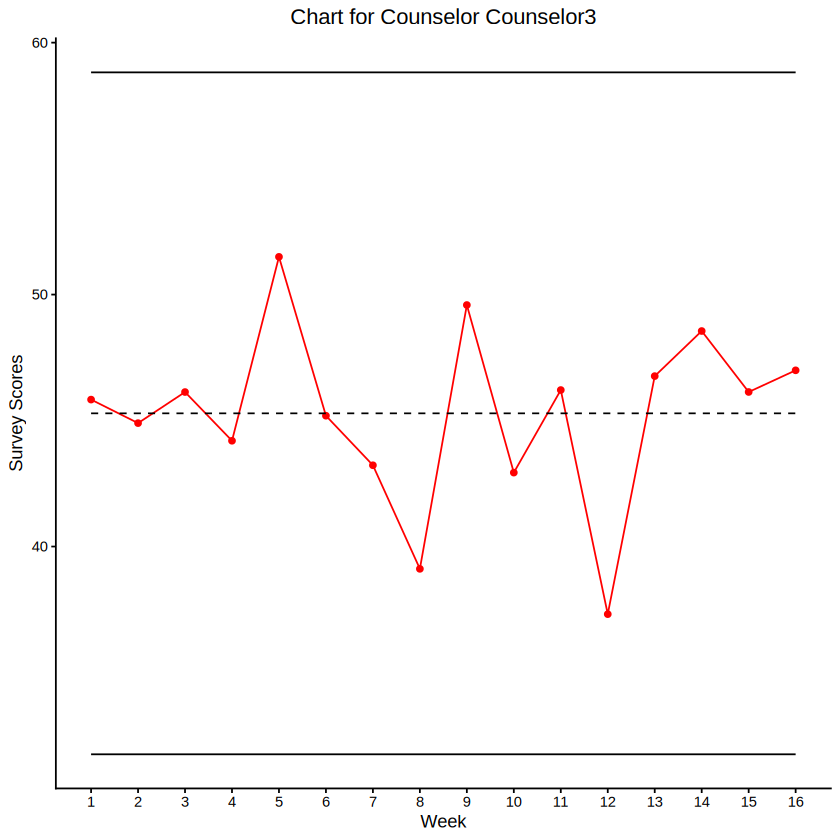

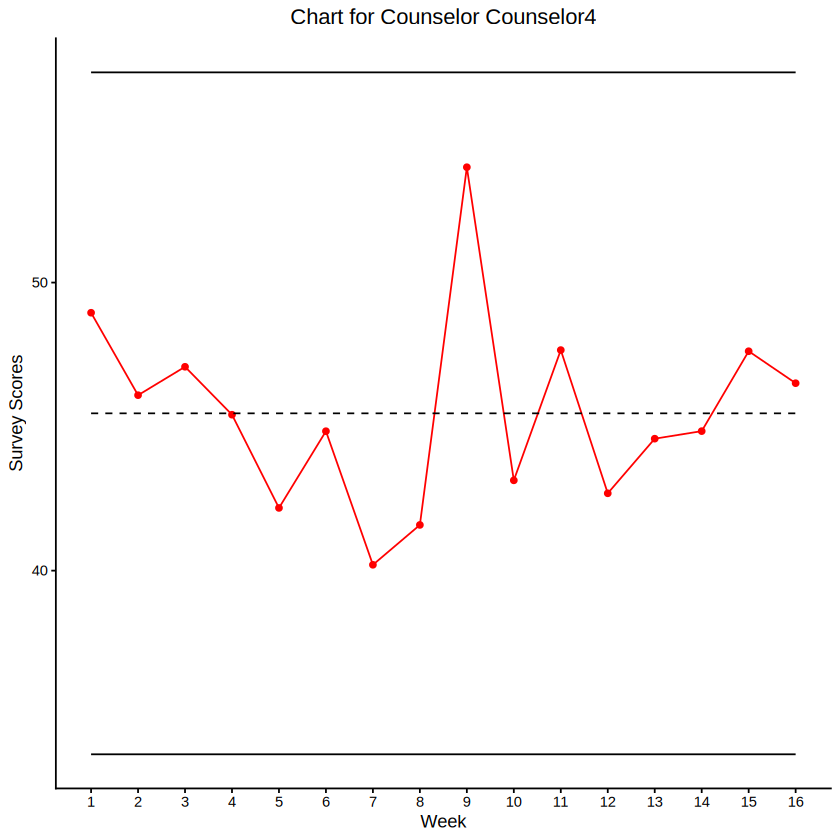

In [29]:
## Notice in the article for the Control Chart for Each Stream Technique,
## in Table 3, if we assume that the correlation between each stream is 0,
## which is what we're doing in this example, then the L value we use for
## the control limits when the number of monitored streams is 5 is 3.46 ##

cfes <- lapply(samp_list,FUN=function(x){

  xdbar <- mean(x$Means)

  rbar <- mean(x$Ranges)

  UCL <- xdbar + L*rbar/(d2*sqrt(5))

  LCL <- xdbar - L*rbar/(d2*sqrt(5))

  p1_chart <- x |>
    ggplot(aes(x=Week,y=Means)) +
    geom_point(color='red') + geom_line(color='red') +
    geom_line(aes(y=UCL),color='black') +
    geom_line(aes(y=LCL),color='black') +
    geom_line(aes(y=xdbar),color='black',linetype='dashed') +
    labs(x = "Week", y = "Survey Scores",
         title = paste("Chart for Counselor ",x$Counselor,sep="")) +
    theme_classic()  +
    theme(plot.title=element_text(hjust=0.50)) +
    scale_x_continuous(breaks = seq(1,25))

  info <- list(Center = xdbar,
               Limits = c(LCL,UCL),
               Violations = x |>
                 filter(Means > UCL | Means < LCL) |>
                 select(Week))

  print(p1_chart)

  return(info)

})

### Q10: Perform Phase II analysis using the Control Chart for Each Stream MSP technique. Do we still have evidence of statistical control? If not, which stream(s) (i.e., counselors) may be causing the out-of-control point(s)?

In [ ]:
## Q10 Code ##

### Q11: What is a difference between a multivariate process and a multiple stream process? Given what you found in Q4-Q10, which framing do you think is the more defensible choice for this specific scenario, and why?

### Q12: Provide an overview of your results that you, as the director, could bring to the university's Vice President of Student Affairs. What is the current status of The Owl's Nest program, and what actions (if any) have you taken or would you recommend?